# RM402E – Statistics & Data Analysis
## Group Project: Predicting Credit Card Default

**Group members:** Malak ACHOUAQ, Andrée Camille Manuella BROU, Marie Christelle Anaïs KOUAME, Mariam MEGRINI, Israel MENDEZ AYAVIRI, Evgeniia NAKARIAKOVA (group RM402E_GR04)

**GitHub:** link

**Dataset:** Default of Credit Card Clients – Kaggle / UCI Machine Learning Repository (Yeh, 2009, https://doi.org/10.24432/C55H7Z)

### Introduction

Credit cards are an important source of revenue for banks, but when clients do not pay their bills the bank loses money. In this project we study 30,000 credit card clients of a bank in Taiwan between April and September 2005, and we look at which clients did not pay their bill in October 2005 (default).

**Research question:** Which characteristics and payment habits of a client are linked to default, and can we predict it?

**Our hypotheses**
1. Men and women do not default in the same proportion.
2. The education level is linked to default.
3. Clients who default have a lower credit limit.
4. Default is linked to the age of the client.
5. Clients who were late with their payment in September default more often.
6. The bill of the same clients changed between August and September.

We use a significance level α = 0.05 for all the tests.

---
# 0. Import libraries and upload the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm, shapiro
import statsmodels.api as sm

In [2]:
# upload the csv file from your computer
from google.colab import files
uploaded = files.upload()

In [3]:
# read the csv file
df = pd.read_csv("UCI_Credit_Card.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


**Description of the variables**

| Variable | Meaning |
|---|---|
| ID | number of the client |
| LIMIT_BAL | credit limit in NT dollars |
| SEX | 1 = male, 2 = female |
| EDUCATION | 1 = graduate school, 2 = university, 3 = high school, 4 = others |
| MARRIAGE | 1 = married, 2 = single, 3 = others |
| AGE | age in years |
| PAY_0, PAY_2 – PAY_6 | payment status in September, August, ... April: -2 = card not used, -1 = paid in full, 0 = minimum paid, 1 to 8 = months of delay |
| BILL_AMT1 – BILL_AMT6 | amount of the bill in September, August, ... April |
| PAY_AMT1 – PAY_AMT6 | amount paid in September, August, ... April |
| default.payment.next.month | 1 = default in October, 0 = no default |

---
# 1. General information on the dataset

In [4]:
# number of rows and columns
print(df.shape)

print("**********************")

df.info()

(30000, 25)
**********************
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AM

In [5]:
# descriptive statistics
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


The dataset has 30,000 clients and 25 columns. All the columns are numerical, but `SEX`, `EDUCATION`, `MARRIAGE` and the `PAY_` columns are in fact categories written with numbers.

---
# 2. Clean the dataset
### 2.1 Missing values

In [6]:
print("Missing values per column:")
df.isna().sum()

Missing values per column:


ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

There are no missing values, so we do not need to fill anything.

### 2.2 Duplicates

In [7]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


There are no duplicated rows.

### 2.3 Remove and rename columns

In [8]:
# ID is only the number of the client, it is not useful for the analysis
df = df.drop(columns=["ID"])

# shorter name for the target, and PAY_0 becomes PAY_1 to follow BILL_AMT1 and PAY_AMT1
df = df.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"})
df.columns

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default'],
      dtype='str')

### 2.4 Check the categories

In [9]:
df["EDUCATION"].value_counts()

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [10]:
df["MARRIAGE"].value_counts()

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

In the documentation, `EDUCATION` goes from 1 to 4 and `MARRIAGE` from 1 to 3. But we also find the codes 0, 5 and 6 for education and 0 for marriage. We do not know what they mean, so we put them in the category "others".

In [11]:
df["EDUCATION"] = df["EDUCATION"].replace([0, 5, 6], 4)
df["MARRIAGE"] = df["MARRIAGE"].replace(0, 3)

print(df["EDUCATION"].value_counts())
print(df["MARRIAGE"].value_counts())

EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
2    15964
1    13659
3      377
Name: count, dtype: int64


### 2.5 New columns

In [12]:
# names instead of numbers, easier to read in the charts
df["sex_name"] = df["SEX"].replace({1: "Male", 2: "Female"})
df["education_name"] = df["EDUCATION"].replace({1: "Graduate", 2: "University", 3: "High school", 4: "Others"})

# age groups
df["age_group"] = pd.cut(df["AGE"], bins=[20, 30, 40, 50, 60, 80], labels=["21-30", "31-40", "41-50", "51-60", "61+"])

# number of months with a delay (PAY >= 1) during the 6 months
pay_cols = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["months_late"] = (df[pay_cols] >= 1).sum(axis=1)

df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,sex_name,education_name,age_group,months_late
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,689.0,0.0,0.0,0.0,0.0,1,Female,University,21-30,2
1,120000.0,2,2,2,26,-1,2,0,0,0,...,1000.0,1000.0,1000.0,0.0,2000.0,1,Female,University,21-30,2
2,90000.0,2,2,2,34,0,0,0,0,0,...,1500.0,1000.0,1000.0,1000.0,5000.0,0,Female,University,31-40,0
3,50000.0,2,2,1,37,0,0,0,0,0,...,2019.0,1200.0,1100.0,1069.0,1000.0,0,Female,University,31-40,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,36681.0,10000.0,9000.0,689.0,679.0,0,Male,University,51-60,0


**Cleaning result comments.** The dataset was already clean: no missing values and no duplicates. We removed `ID`, renamed two columns, grouped the unknown codes of education and marriage into "others" and created 4 new columns. We keep the 30,000 clients.

We also notice some negative bills (`BILL_AMT`). This happens when a client paid more than his bill, so we keep them.

In [13]:
# save the clean dataset
df.to_csv("UCI_Credit_Card_clean.csv", index=False)

# download it to your computer (Google Colab)
files.download("UCI_Credit_Card_clean.csv")

---
# 3. Descriptive statistics and visualisation
### 3.1 The target variable

In [14]:
df["default"].value_counts()

default
0    23364
1     6636
Name: count, dtype: int64

In [15]:
print("Default rate =", df["default"].mean())

Default rate = 0.2212


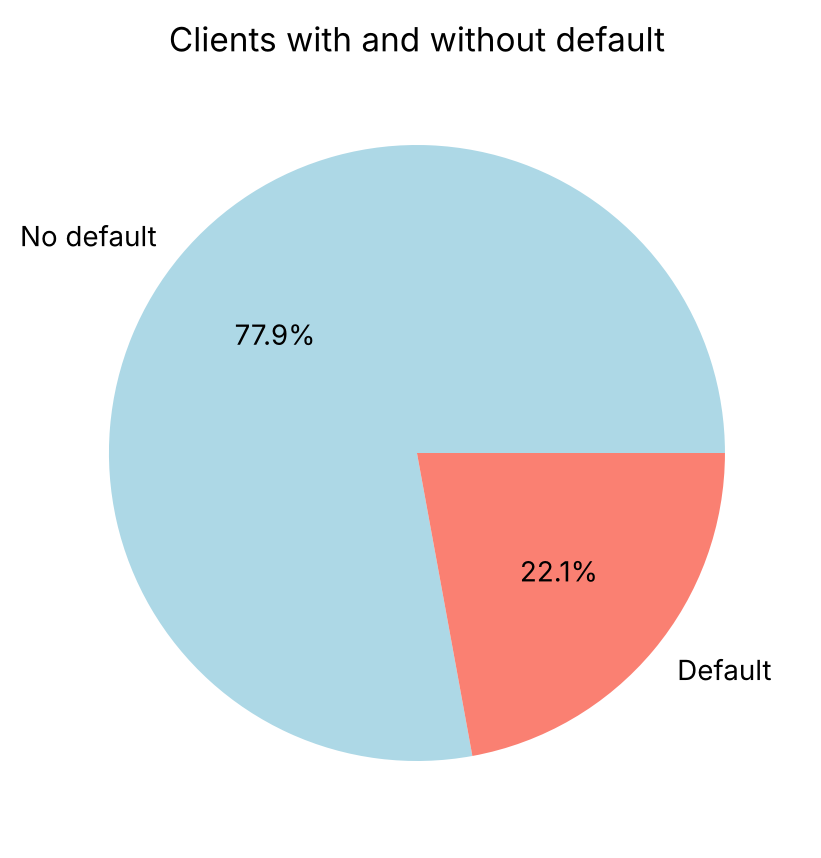

In [16]:
plt.figure(figsize=(5, 5))
plt.pie(df["default"].value_counts(), labels=["No default", "Default"], autopct="%1.1f%%", colors=["lightblue", "salmon"])
plt.title("Clients with and without default")
plt.show()

22.1% of the clients defaulted (6,636 clients) and 77.9% did not (23,364 clients). The two groups do not have the same size. This is important for the machine learning part: a model that always predicts "no default" would already be right 77.9% of the time.

### 3.2 Comparison of the two groups

In [17]:
df.groupby("default")[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "months_late"]].mean()

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1,months_late
default,,,,,
0,178099.726074,35.417266,51994.227273,6307.337357,0.504194
1,130109.656420,35.725738,48509.162297,3397.044153,1.996082


In [18]:
df.groupby("default")[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "months_late"]].median()

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1,months_late
default,,,,,
0,150000.0,34.0,23119.5,2459.5,0.0
1,90000.0,34.0,20185.0,1636.0,1.0


- Clients who default have a **lower credit limit**: mean 130,110 against 178,100, median 90,000 against 150,000.
- They **pay less** in September (median 1,636 against 2,460) while their bill is almost the same.
- They were **late much more often**: 2 months out of 6 on average, against 0.5 for the others.
- The age is the same in the two groups (median 34).

### 3.3 Distribution of the credit limit

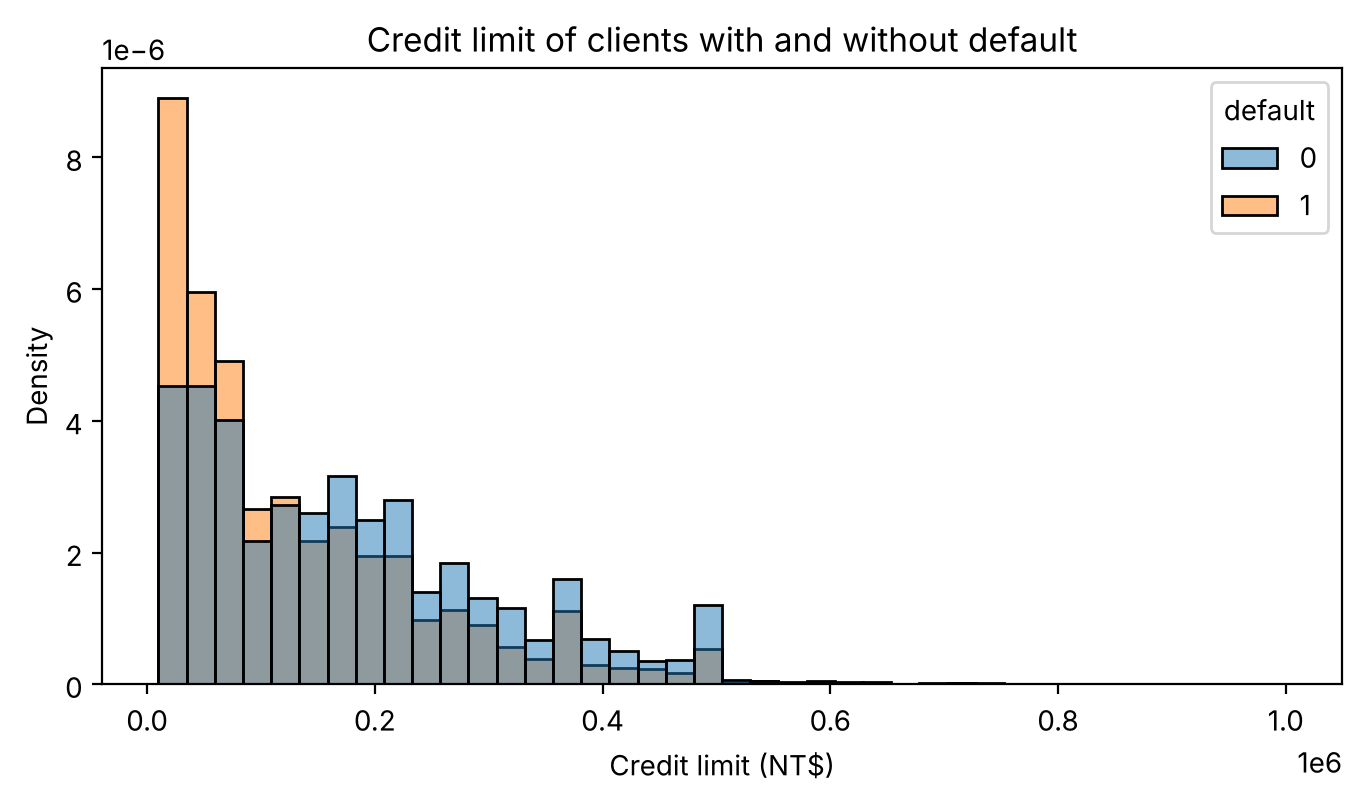

In [19]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="LIMIT_BAL", hue="default", bins=40, stat="density", common_norm=False)
plt.title("Credit limit of clients with and without default")
plt.xlabel("Credit limit (NT$)")
plt.show()

The distribution is skewed to the right: most clients have a small limit and a few have a very high one. The defaulters (orange) are more concentrated on small limits.

### 3.4 Default rate by sex and by education

In [20]:
pd.crosstab(df["sex_name"], df["default"], normalize="index")

default,0,1
sex_name,,
Female,0.792237,0.207763
Male,0.758328,0.241672


In [21]:
pd.crosstab(df["education_name"], df["default"], normalize="index")

default,0,1
education_name,,
Graduate,0.807652,0.192348
High school,0.748424,0.251576
Others,0.929487,0.070513
University,0.762651,0.237349


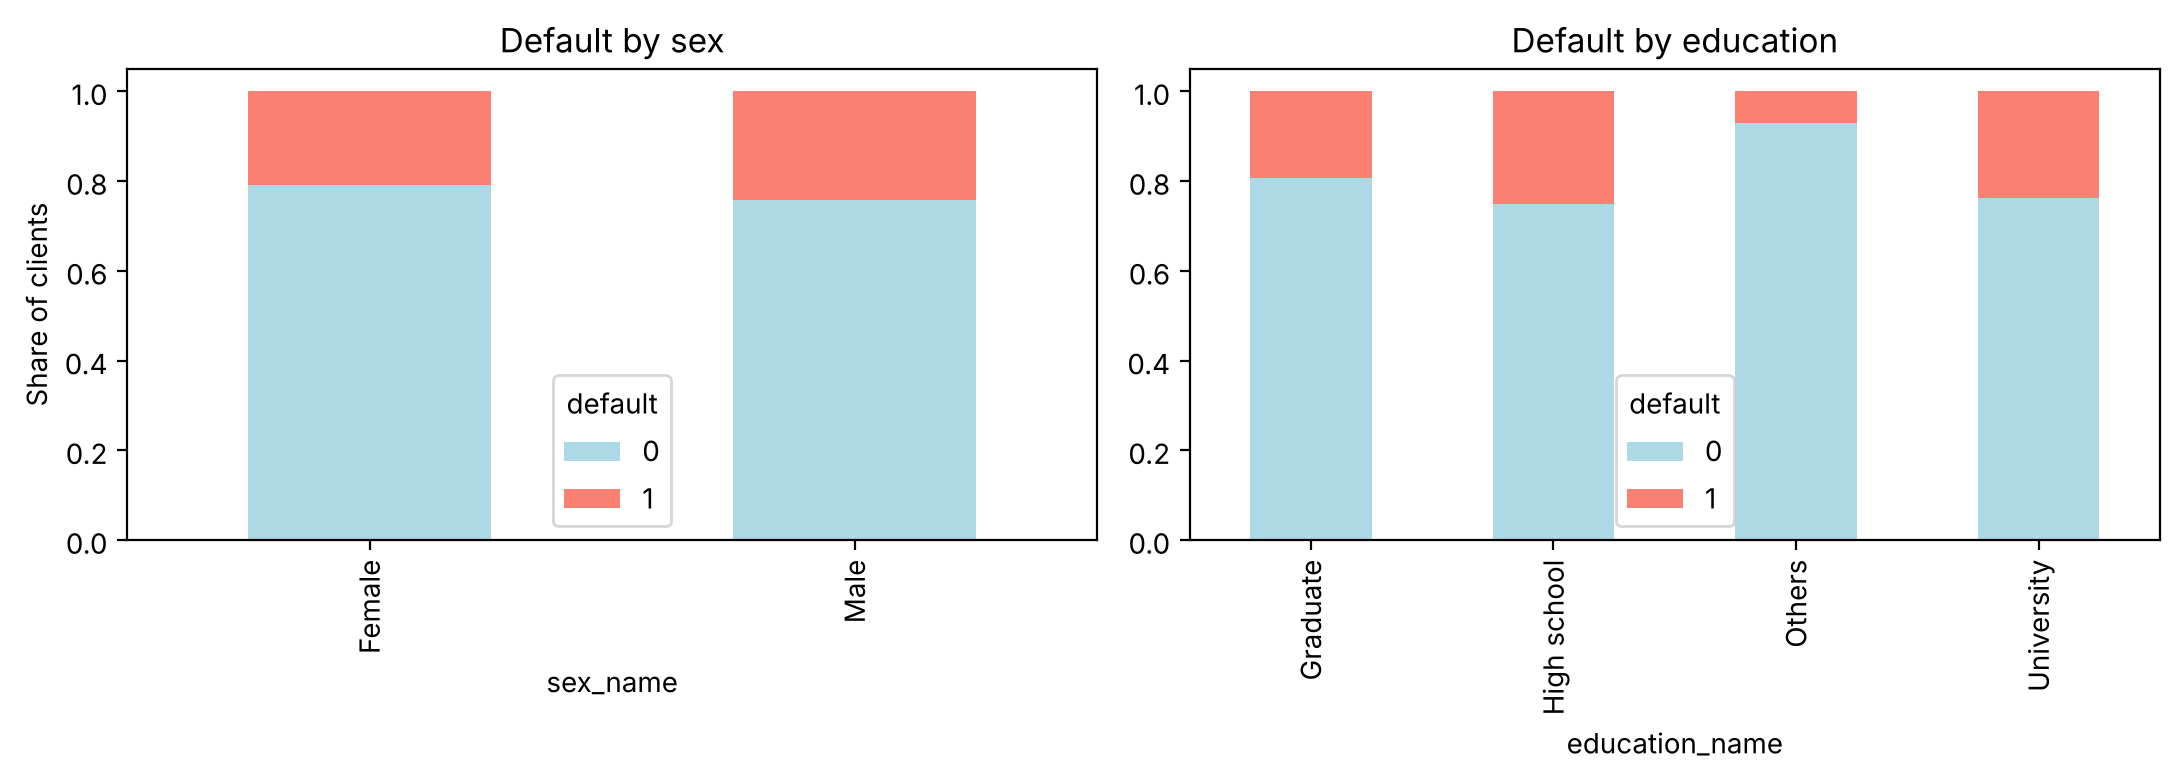

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

pd.crosstab(df["sex_name"], df["default"], normalize="index").plot(kind="bar", stacked=True, ax=axes[0], color=["lightblue", "salmon"])
axes[0].set_title("Default by sex")
axes[0].set_ylabel("Share of clients")

pd.crosstab(df["education_name"], df["default"], normalize="index").plot(kind="bar", stacked=True, ax=axes[1], color=["lightblue", "salmon"])
axes[1].set_title("Default by education")

plt.tight_layout()
plt.show()

Men default a little more than women (24.2% against 20.8%). Clients with a high school education default more (25.2%) than graduate clients (19.2%). The group "Others" is very small (468 clients). The differences exist but they are not very large.

### 3.5 Default rate by age group

In [23]:
age_default = df.groupby("age_group", observed=True)["default"].mean()
age_default

age_group
21-30    0.224371
31-40    0.204331
41-50    0.232973
51-60    0.252379
61+      0.268382
Name: default, dtype: float64

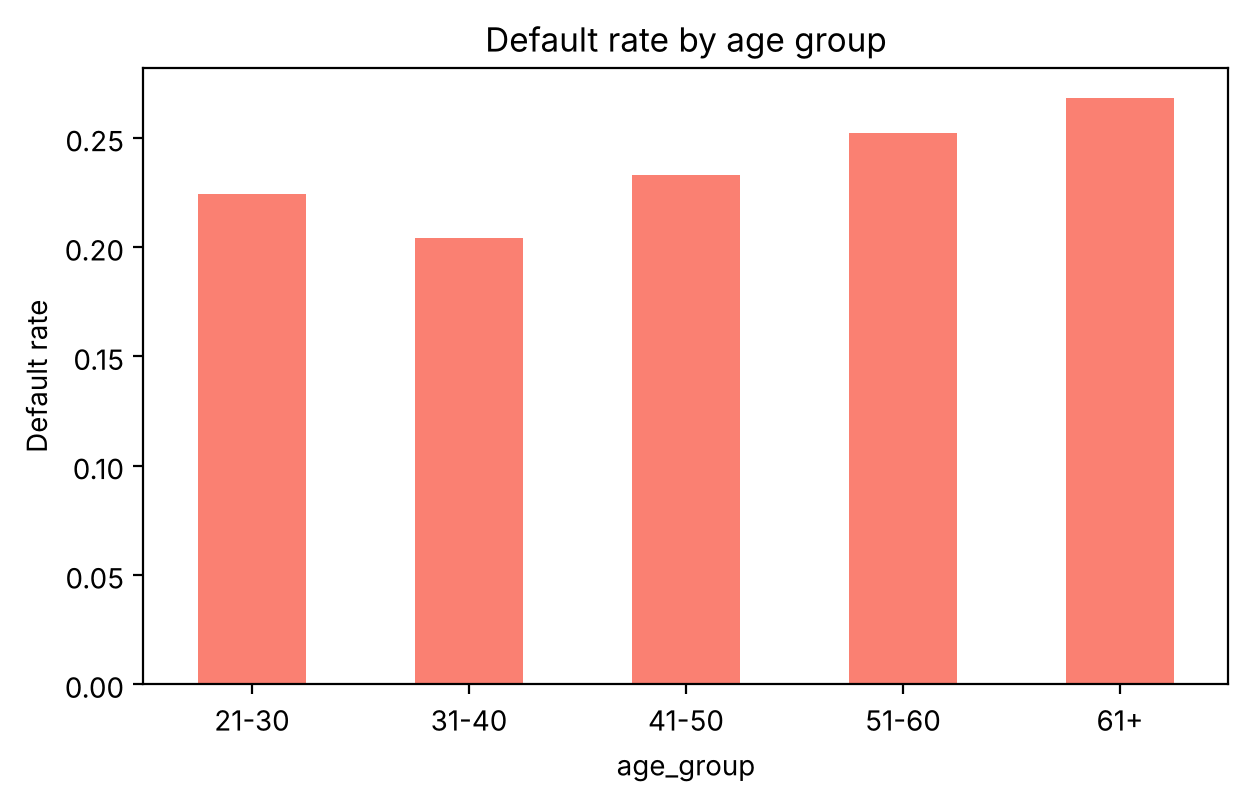

In [24]:
age_default.plot(kind="bar", color="salmon", figsize=(7, 4))
plt.title("Default rate by age group")
plt.ylabel("Default rate")
plt.xticks(rotation=0)
plt.show()

Clients aged 31–40 default the least (20.4%). The default rate increases for older clients and reaches 26.8% for clients over 60 (but this group has only 272 clients).

### 3.6 Payment history

In [25]:
# default rate by payment status in September
pay_default = df.groupby("PAY_1")["default"].mean()
pay_default

PAY_1
-2    0.132294
-1    0.167781
 0    0.128113
 1    0.339479
 2    0.691414
 3    0.757764
 4    0.684211
 5    0.500000
 6    0.545455
 7    0.777778
 8    0.578947
Name: default, dtype: float64

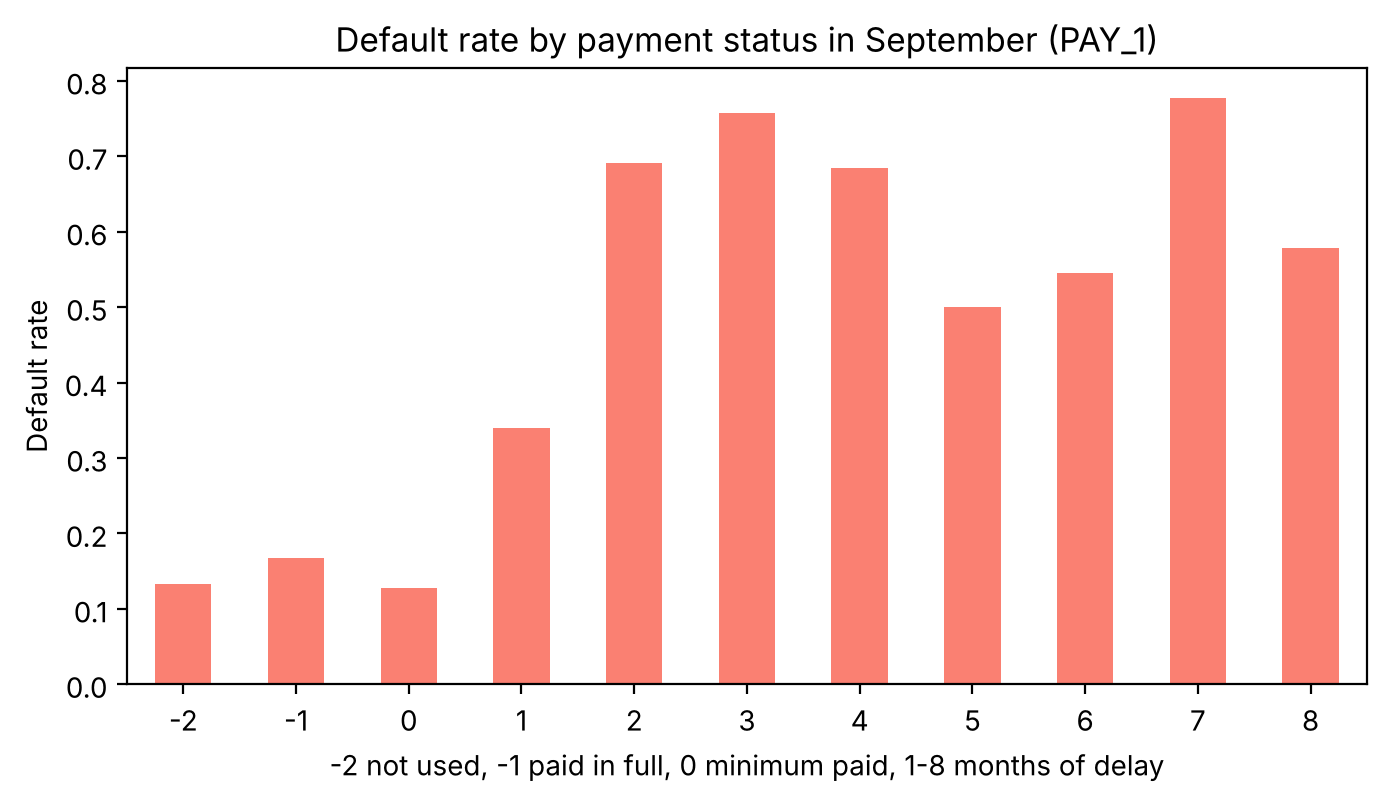

In [26]:
pay_default.plot(kind="bar", color="salmon", figsize=(8, 4))
plt.title("Default rate by payment status in September (PAY_1)")
plt.xlabel("-2 not used, -1 paid in full, 0 minimum paid, 1-8 months of delay")
plt.ylabel("Default rate")
plt.xticks(rotation=0)
plt.show()

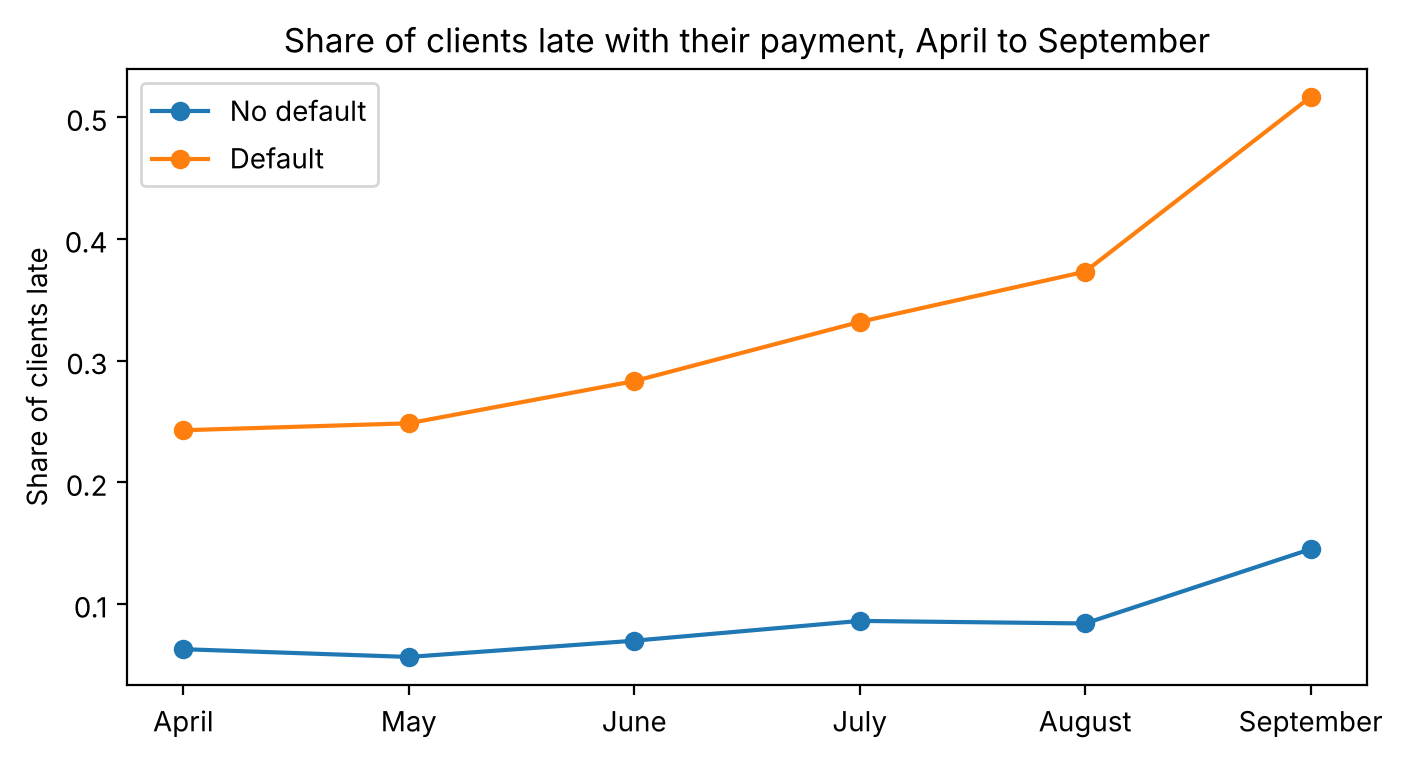

In [27]:
# share of clients who were late each month, for the two groups
months = ["April", "May", "June", "July", "August", "September"]
late_no_default = []
late_default = []
for col in ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_1"]:
    late_no_default.append((df[df["default"] == 0][col] >= 1).mean())
    late_default.append((df[df["default"] == 1][col] >= 1).mean())

plt.figure(figsize=(8, 4))
plt.plot(months, late_no_default, marker="o", label="No default")
plt.plot(months, late_default, marker="o", label="Default")
plt.title("Share of clients late with their payment, April to September")
plt.ylabel("Share of clients late")
plt.legend()
plt.show()

This is the clearest result of the analysis.
- Clients who paid on time in September (codes -2, -1, 0) default in 13% to 17% of the cases. Clients with 2 months of delay default in 69% of the cases.
- The line chart shows that the future defaulters were already late much more often from April, and that their situation gets worse until September.

The payment history seems much more important than the age, the sex or the education.

### 3.7 Correlation

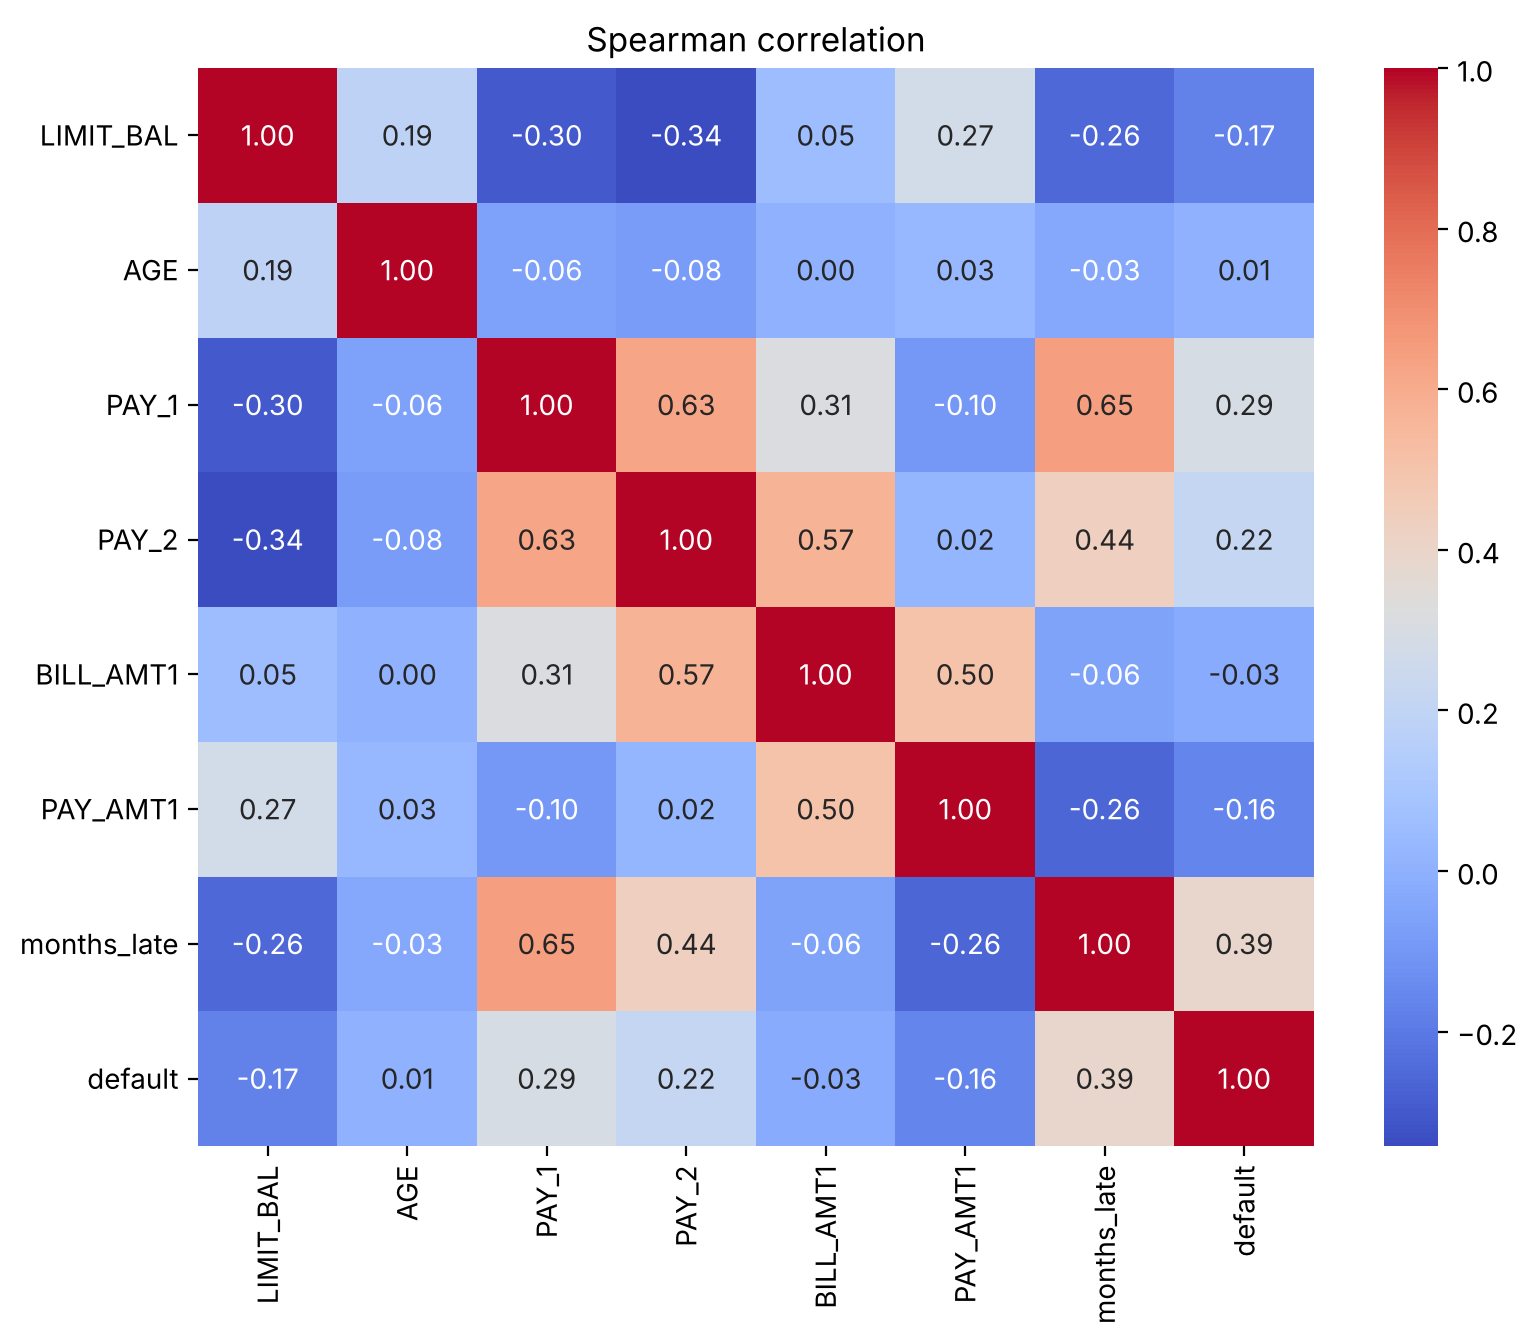

In [28]:
corr = df[["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "BILL_AMT1", "PAY_AMT1", "months_late", "default"]].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Spearman correlation")
plt.show()

We use the Spearman correlation because the variables are not normal (see section 4).
- The strongest correlation with default is `months_late` (0.39), then `PAY_1` (0.29): a moderate positive correlation.
- `LIMIT_BAL` (-0.17) and `PAY_AMT1` (-0.16) have a weak negative correlation with default.
- `AGE` has no correlation with default (0.01).
- `PAY_1` and `PAY_2` are strongly correlated with each other (0.79): a client late one month is often late the next month.

A correlation does not prove a cause.

---
# 4. Normal distribution
### 4.1 Normality test on the credit limit

H0: the credit limit follows a normal distribution

H1: the credit limit does not follow a normal distribution

In [29]:
# the Shapiro test works for samples up to 5,000 values, so we take a random sample
sample = df["LIMIT_BAL"].sample(5000, random_state=0)
stat, p = shapiro(sample)
print("Shapiro p = ", p)

Shapiro p =  5.761803059191613e-49


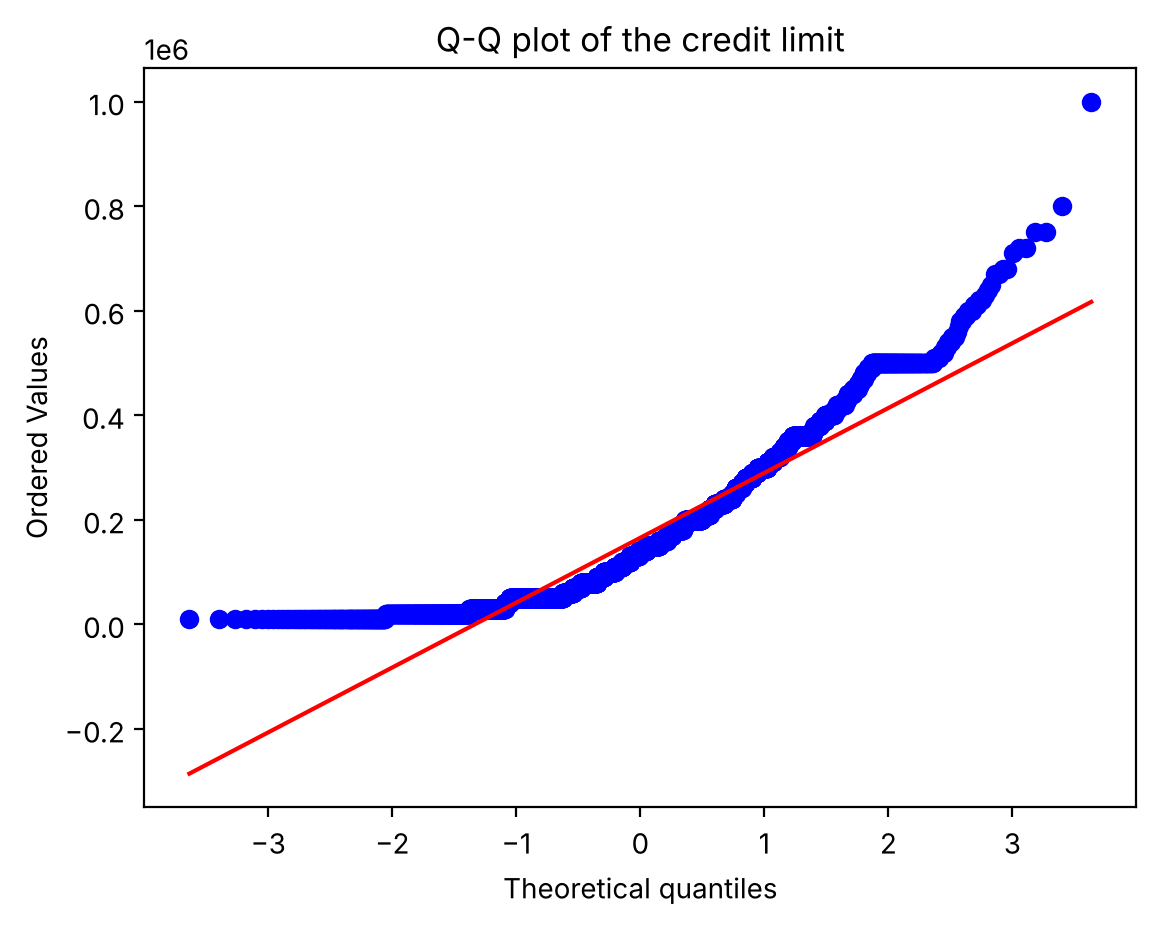

In [30]:
stats.probplot(sample, dist="norm", plot=plt)
plt.title("Q-Q plot of the credit limit")
plt.show()

p-value < 0.05, so we reject H0. The credit limit is **not normal**, and the Q-Q plot moves away from the line. So we cannot use `norm.cdf` on the credit limit itself. We compute the probabilities directly with the data.

In [31]:
# probability that a client has a credit limit higher than 200,000
print("P(LIMIT_BAL > 200,000) =", (df["LIMIT_BAL"] > 200000).mean())

P(LIMIT_BAL > 200,000) = 0.3207333333333333


In [32]:
# minimum limit of the 10% of clients with the highest limit
print("90th percentile =", df["LIMIT_BAL"].quantile(0.90))

90th percentile = 360000.0


32.1% of the clients have a credit limit higher than 200,000, and the 10% of clients with the highest limits have at least 360,000.

### 4.2 Conditional probabilities

In [33]:
print("P(default) =", df["default"].mean())
print("P(default | late in September) =", df[df["PAY_1"] >= 1]["default"].mean())
print("P(default | not late in September) =", df[df["PAY_1"] <= 0]["default"].mean())

P(default) = 0.2212
P(default | late in September) = 0.5029334115576415
P(default | not late in September) = 0.13834009145026313


If a client was late in September, the probability of default is 0.50 instead of 0.14 for a client who was not late: it is about 3.6 times higher.

### 4.3 Normal distribution of the mean (Central Limit Theorem)

The credit limit is not normal, but the mean of many samples should be normal. We take 1,000 random samples of 100 clients and compute the mean credit limit of each sample.

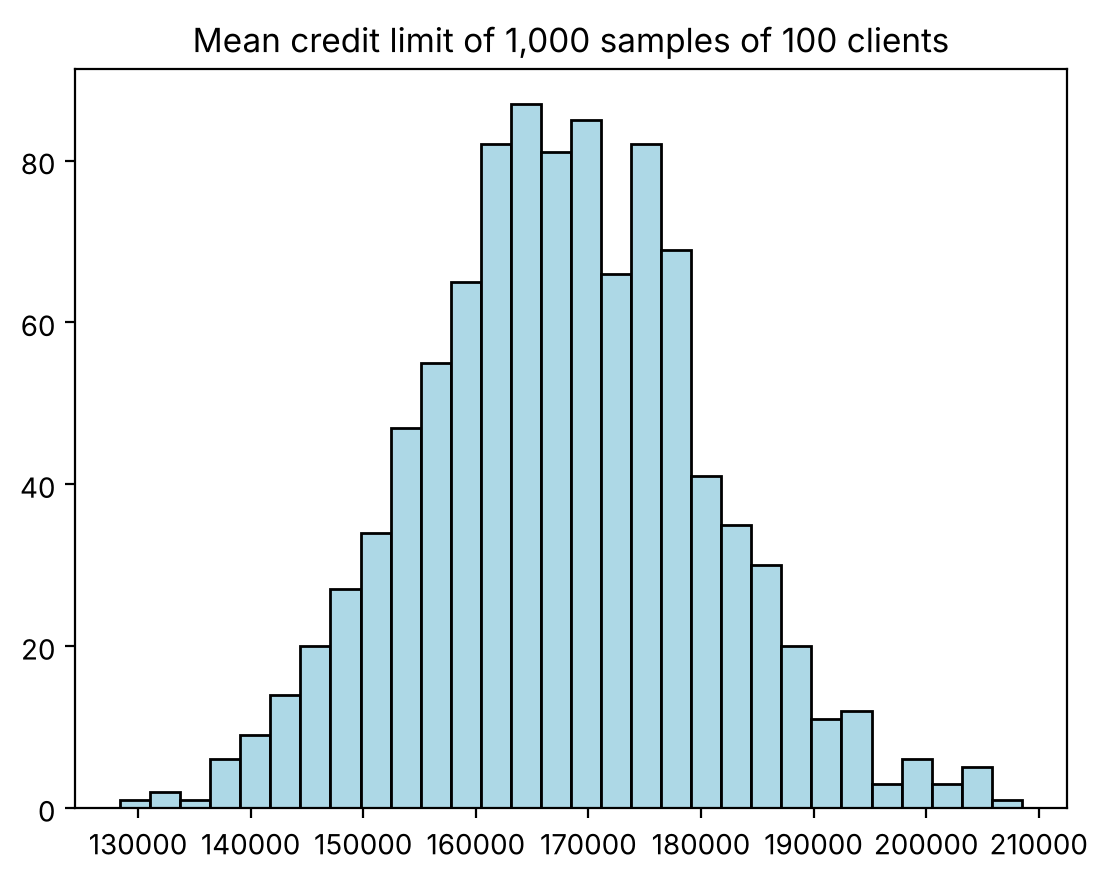

In [34]:
np.random.seed(0)
means = []
for i in range(1000):
    one_sample = np.random.choice(df["LIMIT_BAL"], size=100)
    means.append(one_sample.mean())

plt.hist(means, bins=30, color="lightblue", edgecolor="black")
plt.title("Mean credit limit of 1,000 samples of 100 clients")
plt.show()

In [35]:
stat, p = shapiro(means)
print("Shapiro p = ", p)

Shapiro p =  0.39966871000267307


p-value > 0.05, so we do not reject H0: the means of the samples follow a normal distribution. Now we can use the normal distribution, with mean μ and standard deviation σ/√n.

In [36]:
mu = df["LIMIT_BAL"].mean()
sigma = df["LIMIT_BAL"].std() / np.sqrt(100)
print("mu =", mu)
print("sigma =", sigma)

mu = 167484.32266666667
sigma = 12974.76615672024


In [37]:
# probability that the mean limit of 100 clients is higher than 180,000
p180 = norm.sf(180000, mu, sigma)
print(p180)

0.16736839228810446


In [38]:
p180 = 1 - norm.cdf(180000, mu, sigma)
print(p180)

0.1673683922881044


In [39]:
# probability that the mean limit of 100 clients is between 150,000 and 170,000
p_between = norm.cdf(170000, mu, sigma) - norm.cdf(150000, mu, sigma)
print(p_between)

0.48796959931405787


In [40]:
# value of the mean that is exceeded only 5% of the time
x95 = norm.ppf(0.95, mu, sigma)
print(x95)

188825.91383839518


**Interpretation.**
- The mean limit of a group of 100 clients is higher than 180,000 with a probability of 0.167 (`norm.sf` and `1 - norm.cdf` give the same result).
- It is between 150,000 and 170,000 with a probability of about 0.49.
- Only 5% of the groups of 100 clients have a mean limit higher than about 188,800.

---
# 5. Confidence intervals
### 5.1 Confidence interval for the default rate

In [41]:
n = len(df)
p = df["default"].mean()
se = np.sqrt(p * (1 - p) / n)

print("Default rate =", p)
print("95% CI = [", p - 1.96 * se, ",", p + 1.96 * se, "]")

Default rate = 0.2212
95% CI = [ 0.21650321179493903 , 0.22589678820506098 ]


We are 95% confident that the default rate of all the clients of the bank is between 21.65% and 22.59%.

### 5.2 Confidence interval for the mean credit limit of each group

In [42]:
limit_no_default = df[df["default"] == 0]["LIMIT_BAL"]
limit_default = df[df["default"] == 1]["LIMIT_BAL"]

In [43]:
ci_no_default = stats.t.interval(0.95, len(limit_no_default) - 1, loc=limit_no_default.mean(), scale=stats.sem(limit_no_default))
print("No default: mean =", limit_no_default.mean(), " 95% CI =", ci_no_default)

No default: mean = 178099.72607430234  95% CI = (np.float64(176411.82705267423), np.float64(179787.62509593045))


In [44]:
ci_default = stats.t.interval(0.95, len(limit_default) - 1, loc=limit_default.mean(), scale=stats.sem(limit_default))
print("Default: mean =", limit_default.mean(), " 95% CI =", ci_default)

Default: mean = 130109.65641952984  95% CI = (np.float64(127333.14684718306), np.float64(132886.16599187662))


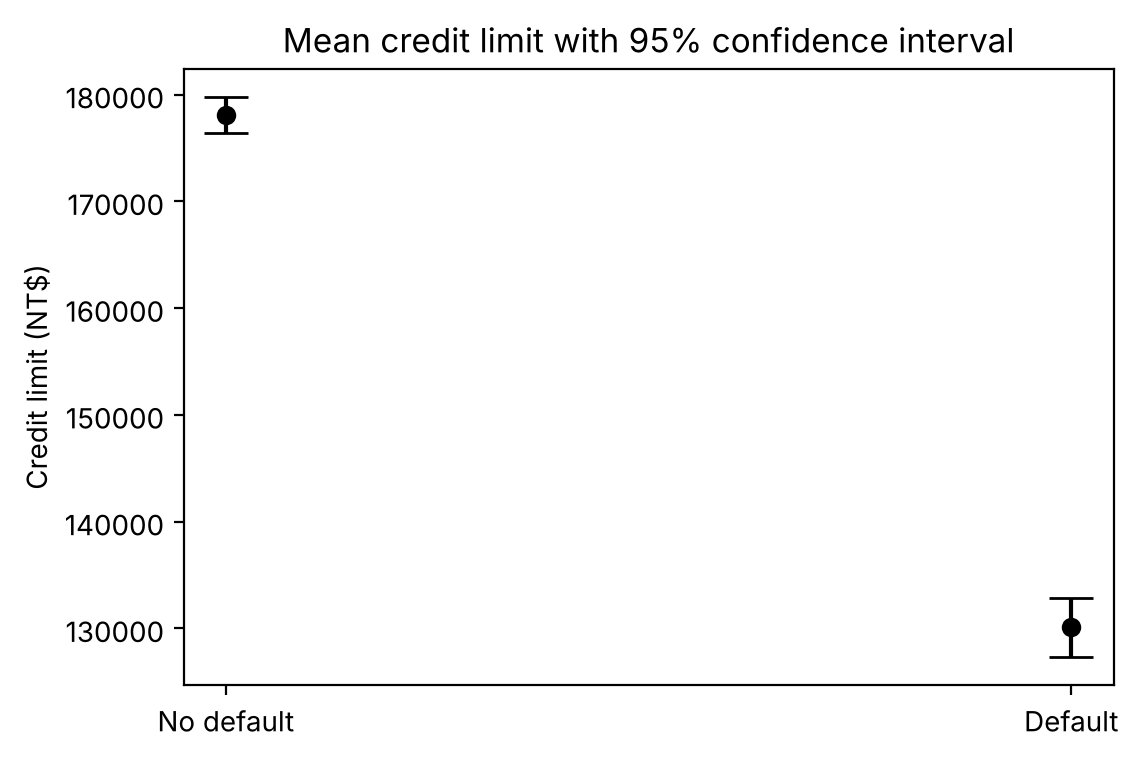

In [45]:
plt.figure(figsize=(6, 4))
plt.errorbar(["No default", "Default"], [limit_no_default.mean(), limit_default.mean()],
             yerr=[limit_no_default.mean() - ci_no_default[0], limit_default.mean() - ci_default[0]],
             fmt="o", capsize=8, color="black")
plt.title("Mean credit limit with 95% confidence interval")
plt.ylabel("Credit limit (NT$)")
plt.show()

The mean credit limit is between 176,412 and 179,788 for the clients without default, and between 127,333 and 132,886 for the clients with default. The two intervals are far from each other, so the difference is very probably real. We check it with a test in section 6.

---
# 6. Hypothesis testing
### 6.1 Credit limit: clients with default vs without default (hypothesis 3)

The two groups contain different clients, so the samples are **independent**.

H0: the credit limit is the same in the two groups

H1: the credit limit is different

α = 0.05

In [46]:
# normality test of the two groups (samples of 5,000)
p = shapiro(limit_no_default.sample(5000, random_state=0)).pvalue
print("Shapiro no default p = ", p)

p = shapiro(limit_default.sample(5000, random_state=0)).pvalue
print("Shapiro default p = ", p)

Shapiro no default p =  1.838704408379766e-45
Shapiro default p =  3.1645524128617196e-55


In [47]:
# the groups are not normal, so we use the Mann-Whitney U test
p_value = stats.mannwhitneyu(limit_no_default, limit_default)
print("p = ", p_value)

p =  MannwhitneyuResult(statistic=np.float64(95786286.5), pvalue=np.float64(1.2255485818223303e-189))


The two groups are not normal, so we use the Mann-Whitney test instead of the t-test.

p-value < 0.05, so we reject H0. Clients who default have a significantly **lower credit limit** (median 90,000 against 150,000). Hypothesis 3 is confirmed.

### 6.2 Age: clients with default vs without default (hypothesis 4)

H0: the age is the same in the two groups

H1: the age is different

In [48]:
age_no_default = df[df["default"] == 0]["AGE"]
age_default = df[df["default"] == 1]["AGE"]

p = shapiro(age_no_default.sample(5000, random_state=0)).pvalue
print("Shapiro no default p = ", p)

p = shapiro(age_default.sample(5000, random_state=0)).pvalue
print("Shapiro default p = ", p)

Shapiro no default p =  1.6361837497802873e-38
Shapiro default p =  1.6546722002683303e-38


In [49]:
p_value = stats.mannwhitneyu(age_no_default, age_default)
print("p = ", p_value)

p =  MannwhitneyuResult(statistic=np.float64(76966879.5), pvalue=np.float64(0.3725035434898616))


p-value > 0.05, so we fail to reject H0. There is **no significant difference** of age between the two groups (median 34 in both).

But the age can still have an effect that is not a straight line: in section 3.5 the youngest and the oldest clients defaulted more. We test the age **groups** with a chi-square test.

In [50]:
table_age = pd.crosstab(df["age_group"], df["default"])
chi2, p_value, dof, expected = stats.chi2_contingency(table_age)
print(table_age)
print("chi2 =", chi2, " p =", p_value)

default       0     1
age_group            
21-30      8542  2471
31-40      8524  2189
41-50      4606  1399
51-60      1493   504
61+         199    73
chi2 = 37.953472730339534  p = 1.1455990644528495e-07


p-value < 0.05, so we reject H0: the default rate is not the same in all the age groups. Hypothesis 4 is confirmed for the age groups, but the effect is small (from 20.4% to 26.8%).

### 6.3 Sex and default (hypothesis 1) – chi-square test

We compare two categorical variables, so we use the **chi-square test of independence**.

H0: default and sex are independent

H1: default and sex are associated

In [51]:
table_sex = pd.crosstab(df["sex_name"], df["default"])
table_sex

default,0,1
sex_name,,
Female,14349,3763
Male,9015,2873


In [52]:
chi2, p_value, dof, expected = stats.chi2_contingency(table_sex)
print("chi2 =", chi2)
print("p =", p_value)
print("expected values:")
print(expected)

chi2 = 47.708796890621116
p = 4.944678999412026e-12
expected values:
[[14105.6256  4006.3744]
 [ 9258.3744  2629.6256]]


If sex had no effect, we would expect 2,630 men with a default. We observe 2,873.

p-value < 0.05, so we reject H0. Men default a little more often than women (24.2% against 20.8%). Hypothesis 1 is confirmed, but the difference is small. Sex should not be used to give or refuse a credit.

### 6.4 Education and default (hypothesis 2) – chi-square test

H0: default and education are independent

H1: default and education are associated

In [53]:
table_edu = pd.crosstab(df["education_name"], df["default"])
chi2, p_value, dof, expected = stats.chi2_contingency(table_edu)
print(table_edu)
print("chi2 =", chi2, " p =", p_value)

default             0     1
education_name             
Graduate         8549  2036
High school      3680  1237
Others            435    33
University      10700  3330
chi2 = 160.40995107224546  p = 1.4950645648106153e-34


p-value < 0.05, so we reject H0. The default rate depends on the education level (19.2% for graduate clients, 25.2% for high school). Hypothesis 2 is confirmed.

### 6.5 Late payment in September and default (hypothesis 5) – chi-square test

H0: default does not depend on being late in September

H1: default depends on being late in September

In [54]:
df["late_september"] = (df["PAY_1"] >= 1).astype(int)
table_late = pd.crosstab(df["late_september"], df["default"])
chi2, p_value, dof, expected = stats.chi2_contingency(table_late)
print(table_late)
print("chi2 =", chi2, " p =", p_value)

default             0     1
late_september             
0               19975  3207
1                3389  3429
chi2 = 4063.187555923154  p = 0.0


p-value < 0.05, so we reject H0. The chi2 (4,063) is much larger than for sex (48) or education (160), so being late in September is much more strongly linked to default. 50% of the clients who were late defaulted, against 14% of the others. Hypothesis 5 is confirmed.

### 6.6 Credit limit and education – Kruskal-Wallis test

We compare more than two groups (4 education levels) and the limit is not normal, so we use the **Kruskal-Wallis test**.

H0: the credit limit is the same for all education levels

H1: at least one education level is different

In [55]:
graduate = df[df["EDUCATION"] == 1]["LIMIT_BAL"]
university = df[df["EDUCATION"] == 2]["LIMIT_BAL"]
high_school = df[df["EDUCATION"] == 3]["LIMIT_BAL"]
others = df[df["EDUCATION"] == 4]["LIMIT_BAL"]

p_value = stats.kruskal(graduate, university, high_school, others)
print("p = ", p_value)

p =  KruskalResult(statistic=np.float64(2382.7500524147667), pvalue=np.float64(0.0))


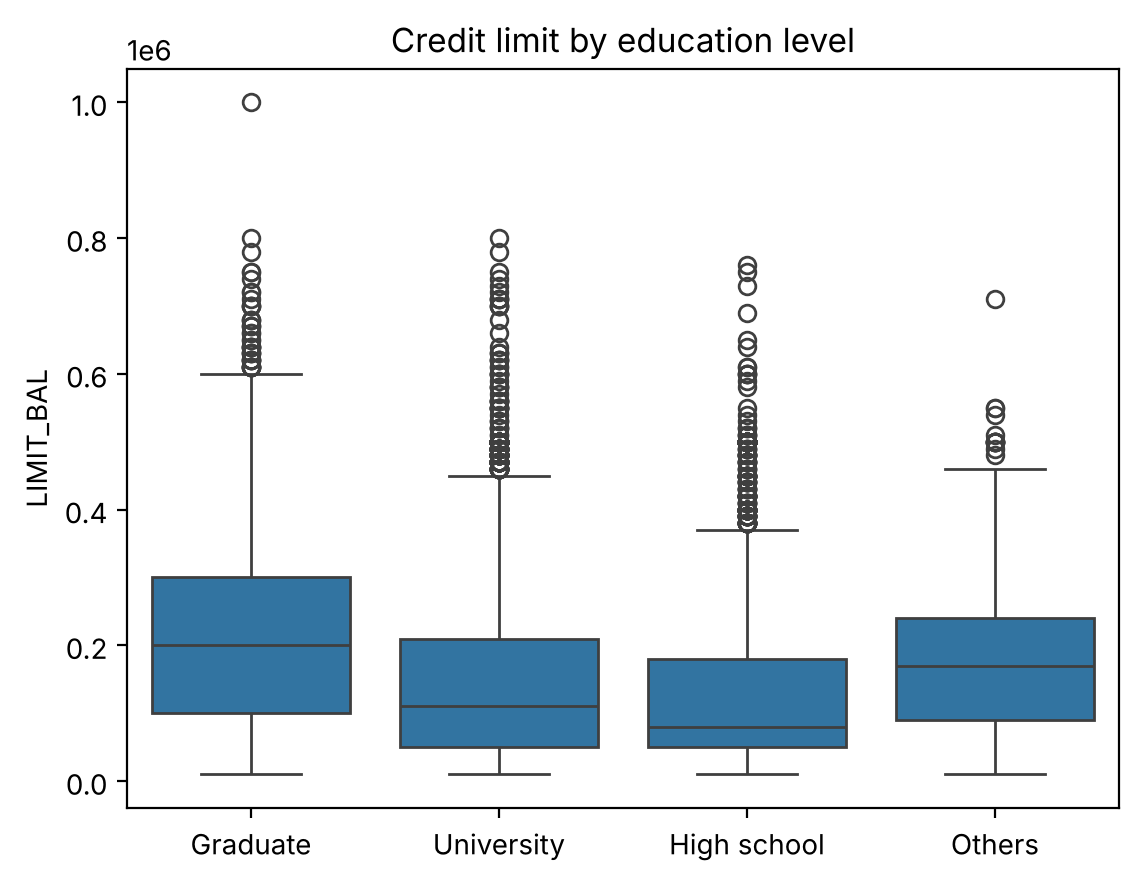

In [56]:
sns.boxplot(data=df, x="education_name", y="LIMIT_BAL", order=["Graduate", "University", "High school", "Others"])
plt.title("Credit limit by education level")
plt.xlabel("")
plt.show()

p-value < 0.05, so we reject H0. Graduate clients receive higher credit limits (median 200,000) than university clients (110,000) and high school clients (80,000).

### 6.7 Bill of September vs bill of August (hypothesis 6)

The two bills are measured on the **same clients**, so the samples are **dependent** (paired).

H0: the mean difference between the two months is 0

H1: the mean difference is not 0

In [57]:
bill_september = df["BILL_AMT1"]
bill_august = df["BILL_AMT2"]

print("Mean bill August =", bill_august.mean())
print("Mean bill September =", bill_september.mean())

Mean bill August = 49179.07516666667
Mean bill September = 51223.3309


In [58]:
# normality test of the differences
difference = bill_september - bill_august
p = shapiro(difference.sample(5000, random_state=0)).pvalue
print("Shapiro p = ", p)

Shapiro p =  2.8205214970249483e-83


In [59]:
# dependent samples and not normal, so we use the Wilcoxon test
p_value = stats.wilcoxon(bill_september, bill_august)
print("p = ", p_value)

p =  WilcoxonResult(statistic=np.float64(177659019.0), pvalue=np.float64(2.397734305504634e-13))


The differences are not normal, so we use the Wilcoxon test instead of the paired t-test.

p-value < 0.05, so we reject H0. The bill of September is higher than the bill of August (51,223 against 49,179 on average, about +2,000 NT$). Hypothesis 6 is confirmed.

### 6.8 Summary of the tests

| Hypothesis | Test | p-value | Decision |
|---|---|---|---|
| 1. Sex and default | Chi-square | < 0.001 | Reject H0 (small difference) |
| 2. Education and default | Chi-square | < 0.001 | Reject H0 (small difference) |
| 3. Credit limit and default | Mann-Whitney | < 0.001 | Reject H0 |
| 4. Age and default | Mann-Whitney / Chi-square | 0.37 / < 0.001 | Fail to reject H0 for the age / Reject H0 for the age groups |
| 5. Late in September and default | Chi-square | < 0.001 | Reject H0 (strongest effect) |
| 6. Bill September vs August | Wilcoxon | < 0.001 | Reject H0 |

---
# 7. Regression
### 7.1 Simple linear regression

The variable `default` is 0 or 1, so a linear regression is not adapted to it. We use the linear regression to answer another question: **what explains the credit limit given by the bank?**

The credit limit is very skewed, so we use its logarithm.

In [60]:
df["log_limit"] = np.log(df["LIMIT_BAL"])

X = df[["AGE"]]
Y = df["log_limit"]

X = sm.add_constant(X)
model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_limit   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     556.9
Date:                Sat, 21 Nov 2026   Prob (F-statistic):          5.19e-122
Time:                        18:57:54   Log-Likelihood:                -40472.
No. Observations:               30000   AIC:                         8.095e+04
Df Residuals:                   29998   BIC:                         8.096e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.1739      0.021    521.789      0.0

- The coefficient of `AGE` is 0.0138 and its p-value is < 0.05: one more year of age is linked to a credit limit about 1.4% higher.
- But the R-squared is only 0.018: the age explains less than 2% of the variation of the credit limit.

### 7.2 Multiple linear regression

In [61]:
# dummy variables for education (graduate is the reference)
df["university"] = (df["EDUCATION"] == 2).astype(int)
df["high_school"] = (df["EDUCATION"] == 3).astype(int)
df["female"] = (df["SEX"] == 2).astype(int)
df["married"] = (df["MARRIAGE"] == 1).astype(int)

X = df[["AGE", "female", "married", "university", "high_school", "months_late"]]
Y = df["log_limit"]

X = sm.add_constant(X)
model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_limit   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.175
Method:                 Least Squares   F-statistic:                     1061.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:57:54   Log-Likelihood:                -37861.
No. Observations:               30000   AIC:                         7.574e+04
Df Residuals:                   29993   BIC:                         7.579e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          11.4266      0.023    498.201      

**Interpretation.**
- The R-squared goes up to 0.175: the model explains about 17.5% of the variation of the credit limit, much more than the age alone. The rest depends on information we do not have (income, savings...).
- All the p-values are < 0.05.
- **Education** has the biggest effect: compared with graduate clients, the limit is lower for university and even lower for high school clients.
- **months_late** has a negative coefficient: each month with a delay is linked to a lower limit.
- Women and married clients have a higher limit.

These are associations, not causes.

---
# 8. Machine learning: predicting default
### 8.1 Prepare the data

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import classification_report

In [63]:
# y variable
y = df["default"]

# x variables: all the original variables + months_late
X = df[["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
        "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
        "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
        "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
        "months_late"]]

In [64]:
# data split (25% for the test). stratify keeps 22% of defaults in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(X_train.shape, X_test.shape)

(22500, 24) (7500, 24)


All the variables are measured from April to September, before the default of October, so there is no data leakage (no variable contains the answer).

### 8.2 Logistic regression

In [65]:
# the variables have very different scales, so we standardise them
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [66]:
# class_weight="balanced" gives more weight to the defaults, because they are only 22% of the clients
logistic_regression = LogisticRegression(max_iter=1000, class_weight="balanced")
logistic_regression.fit(X_train_scaled, y_train)
y_pred = logistic_regression.predict(X_test_scaled)

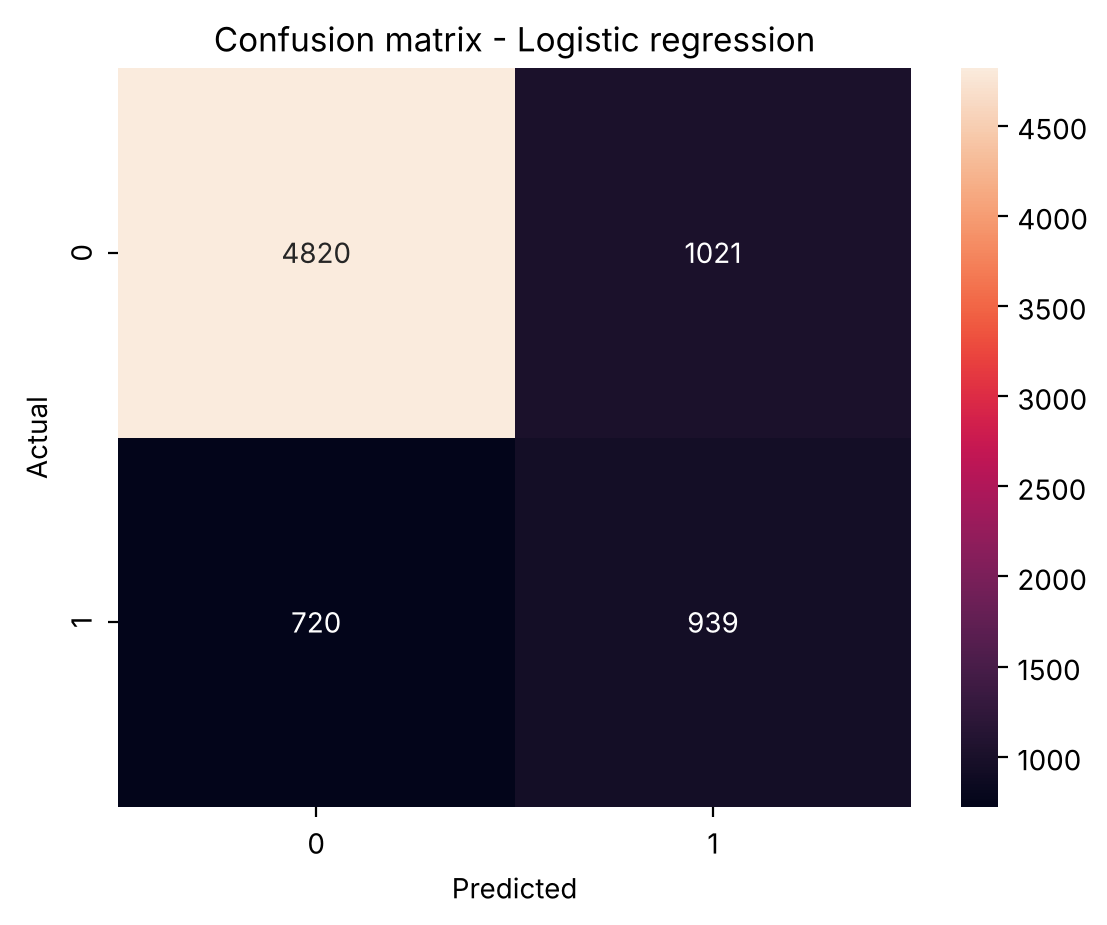

In [67]:
confusion_matrix = pd.crosstab(y_test, y_pred, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(confusion_matrix, annot=True, fmt="d")
plt.title("Confusion matrix - Logistic regression")
plt.show()

In [68]:
print("Accuracy: ", metrics.accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy:  0.7678666666666667
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      5841
           1       0.48      0.57      0.52      1659

    accuracy                           0.77      7500
   macro avg       0.67      0.70      0.68      7500
weighted avg       0.78      0.77      0.77      7500



In [69]:
# importance of the variables = coefficients of the model
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_regression.coef_[0],
    "Abs_Coefficient": abs(logistic_regression.coef_[0])
})
importance = importance.sort_values("Abs_Coefficient", ascending=False)
importance.head(10)

,Feature,Coefficient,Abs_Coefficient
23,months_late,0.890184,0.890184
5,PAY_1,0.292724,0.292724
12,BILL_AMT2,0.262946,0.262946
0,LIMIT_BAL,-0.241436,0.241436
17,PAY_AMT1,-0.215078,0.215078
11,BILL_AMT1,-0.204038,0.204038
13,BILL_AMT3,0.144987,0.144987
18,PAY_AMT2,-0.125404,0.125404
6,PAY_2,-0.108498,0.108498
8,PAY_4,-0.108393,0.108393


**Interpretation.**
- Accuracy = 0.77. The model finds 57% of the clients who really defaulted (recall of class 1 = 0.57). When it predicts a default, it is right in 48% of the cases (precision = 0.48).
- Without `class_weight="balanced"` the accuracy would be higher, but the model would find only about 28% of the defaulters, which is not useful for the bank.
- The most important variables are `months_late` (by far), then `PAY_1`, the bills, the credit limit and the payment of September. A higher limit and a higher payment decrease the risk (negative coefficients).

### 8.3 Random forest

In [70]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=0)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

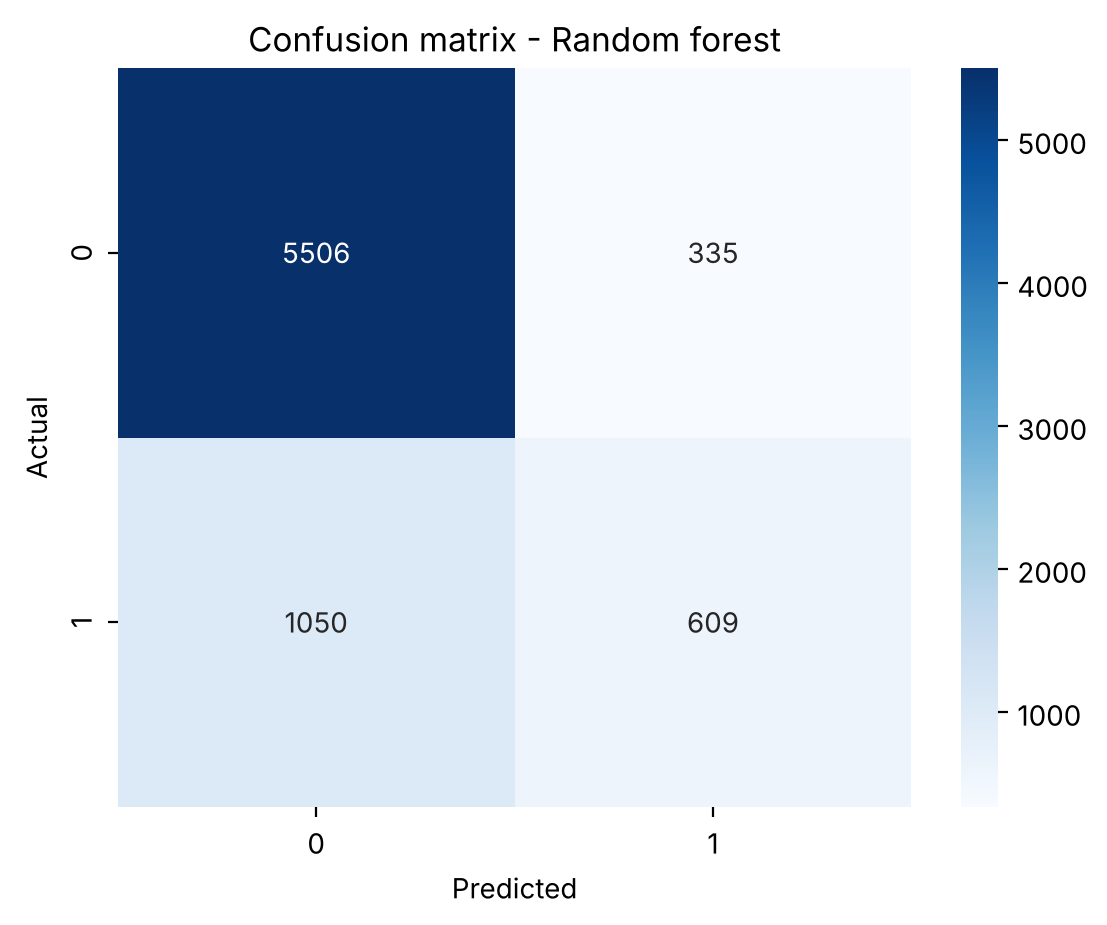

In [71]:
confusion_matrix = pd.crosstab(y_test, y_pred_rf, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion matrix - Random forest")
plt.show()

In [72]:
print("Accuracy: ", metrics.accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy:  0.8153333333333334
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      5841
           1       0.65      0.37      0.47      1659

    accuracy                           0.82      7500
   macro avg       0.74      0.65      0.68      7500
weighted avg       0.80      0.82      0.80      7500



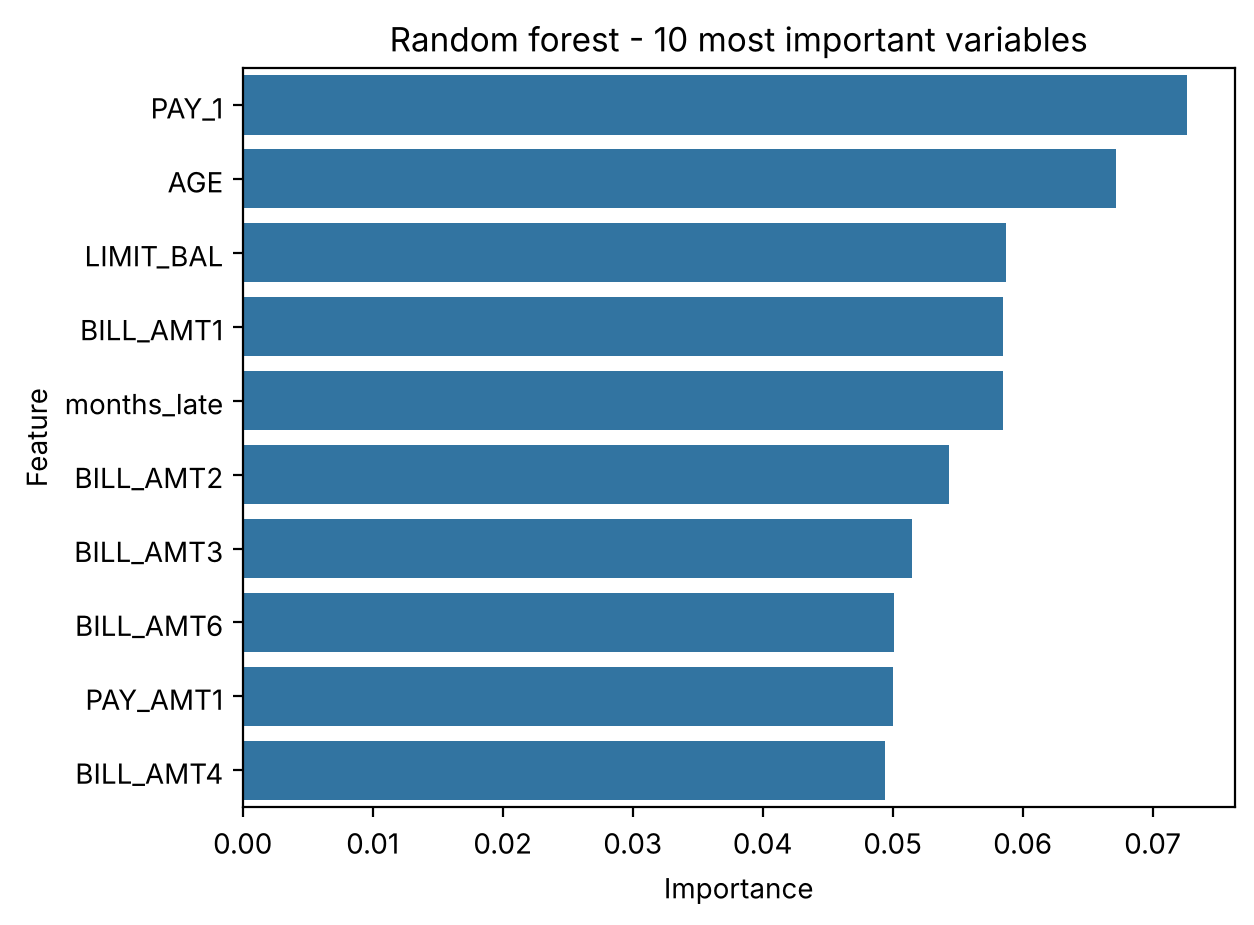

In [73]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

sns.barplot(data=feature_importance.head(10), x="Importance", y="Feature")
plt.title("Random forest - 10 most important variables")
plt.show()

**Interpretation.**
- Accuracy = 0.82, higher than the logistic regression. But the random forest finds only 37% of the defaulters (recall = 0.37). When it predicts a default, it is right in 65% of the cases (precision = 0.65).
- The most important variable is again `PAY_1`, the payment status of September.

### 8.4 Comparison of the two models

| | Accuracy | Precision (default) | Recall (default) | F1-score (default) |
|---|---|---|---|---|
| Logistic regression (balanced) | 0.77 | 0.48 | 0.57 | 0.52 |
| Random forest | 0.82 | 0.65 | 0.37 | 0.47 |

- The random forest has the best accuracy, but it misses more defaulters.
- The logistic regression finds more defaulters (better recall and F1-score), with more false alarms.
- A model that always says "no default" would have an accuracy of 0.78 without finding any defaulter. So accuracy alone is not a good criterion here.
- For a bank, missing a client who will not pay is usually more expensive than checking a good client, so we prefer the **logistic regression** for this problem.

---
# 9. Conclusion

**Research question:** Which characteristics and payment habits of a client are linked to default, and can we predict it?

- **22.1%** of the clients defaulted (95% confidence interval: 21.65% – 22.59%).
- **Payment history is the most important factor.** Clients late in September defaulted in 50% of the cases, against 14% for the others. The number of months with a delay has the strongest correlation with default (0.39), and the payment history (`months_late`, `PAY_1`) is the most important information in both models.
- **Credit limit:** clients who default have a lower credit limit (Mann-Whitney, p < 0.05).
- **Profile of the client:** sex, education and age groups are significantly linked to default, but the differences are small (between about 19% and 27%). The age alone is not different between the two groups.
- **Credit limit given by the bank:** it depends mostly on education and on past delays, but our regression explains only about 17.5% of it.
- **Prediction:** the models predict default better than chance, but not perfectly. The balanced logistic regression finds 57% of the defaulters, the random forest has the best accuracy (0.82).

**Answer:** default is mostly linked to **how the client paid in the previous months**, much more than to who the client is.

**Limitations**
- The data come from one bank in Taiwan in 2005, so the results may not be the same today or in another country.
- We have only 6 months of history and no information about income.
- With 30,000 clients, even small differences are significant.
- Using sex, age or marital status to decide a credit raises ethical and legal problems.